# Clasificación Supervisada de Consultas Médicas para la Red de Prestadores (Humana S.A.)

**Autor:** Adrián Bravo  
**Materia:** Aprendizaje Supervisado

## 1. Introducción

Actualmente, la red de prestadores médicos de Humana S.A. cuenta con un gran número de médicos, clínicas y centros de salud a nivel nacional:

<img src="./img/red_prestadores.png" width="500" />

Sin embargo, su buscador web depende de filtros rígidos (ciudad, tipo de servicio y especialidad) que requieren que el paciente conozca exactamente la especialidad médica que necesita. 

<img src="./img/buscador.png" width="500" />

En la práctica, los usuarios describen lo que sienten en lenguaje natural (por ejemplo, dolor de pecho, manchas en la piel o malestar estomacal), lo que suele provocar búsquedas fallidas o derivaciones incorrectas.

El objetivo de este proyecto es desarrollar un modelo de aprendizaje supervisado capaz de clasificar descripciones de síntomas y consultas en texto libre hacia la especialidad médica correspondiente. Esta solución busca mejorar la experiencia del afiliado facilitando un acceso rápido al especialista adecuado y optimizando la derivación dentro de la red de prestadores.

Además, este modelo sirve como base fundamental para el proyecto de titulación en *Large Database Models* (LDMs) y *Relational Deep Learning*, permitiendo evolucionar de consultas tradicionales en SQL hacia búsqueda semántica inteligente sobre bases de datos relacionales.

## 2. Exploratory Data Analysis (EDA)

### 2.1. Metodología de Adquisición y Estrategia de Datos
Para abordar este proyecto contamos con **dos bases de datos independientes**, cada una con su propio origen y flujo de adquisición:

1. **Base de Prestadores (Humana S.A.):** Representa la *oferta médica* real de la aseguradora (médicos, clínicas, especialidades y ciudades), obtenida directamente desde su plataforma web.
2. **Base de Consultas Clínicas (Corpus NLP):** Representa la *demanda de los pacientes* (descripciones de síntomas y motivos de consulta en lenguaje natural), adquirida desde Hugging Face y adaptada al español para entrenar los modelos supervisados.

Los siguientes diagramas detallan el proceso de generación de cada conjunto de datos:

#### 1. Flujo de Obtención: Base de Prestadores (Humana S.A.)
```mermaid
flowchart TD
    A["Portal Web Oficial de Humana S.A."] --> B["Web Scraping Asíncrono (Playwright)"]
    B --> C["Extracción y Limpieza de Atributos\n(nombre, ciudad, servicio, especialidades)"]
    C --> D[("data/prestadores_humana_limpio.csv\n1,025 prestadores médicos")]
```

#### 2. Flujo de Obtención: Consultas Clínicas de Pacientes (NLP)
```mermaid
flowchart TD
    E["Hugging Face Hub\n(HPAI-BSC / medical-specialities)"] --> F["Filtrado por las 6 Especialidades Clave"]
    F --> G["Traducción Neuronal al Español\n(MarianMT Helsinki-NLP)"]
    G --> H[("data/consultas_medicas_es.csv\n1,698 consultas en español")]
```

---

#### Criterio de Selección de Especialidades Médicas
A partir de la oferta médica de Humana, seleccionamos **6 especialidades médicas estratégicas**. Estas especialidades concentran el mayor volumen de consultas ambulatorias y presentan una diferenciación clínica y sintomática idónea para la clasificación supervisada:

| Especialidad (Humana S.A.) | Especialidad (Corpus Original) | Tipo de Patología / Sintomatología Representativa |
| :--- | :--- | :--- |
| **Cardiología** | `Cardiology` | Dolor precordial, palpitaciones, hipertensión, disnea de esfuerzo |
| **Gastroenterología** | `Gastroenterology` | Dolor abdominal, reflujo gastroesofágico, náuseas, diarrea |
| **Pediatría** | `Pediatrics` | Cuadros febriles en lactantes, desarrollo psicomotor, exantemas infantiles |
| **Traumatología** | `Orthopedics` | Lesiones osteoarticulares, fracturas, dolor lumbar y de extremidades |
| **Dermatología** | `Dermatology` | Lesiones cutáneas, prurito, dermatitis, erupciones y lunares |
| **Ginecología** | `Gynecology` | Salud reproductiva femenina, alteraciones menstruales, dolor pélvico |

---

### 2.2. Adquisición de la Oferta Médica mediante Web Scraping
Para obtener la base de prestadores de Humana S.A., se utilizó **Playwright** en modo asíncrono para navegar de manera automatizada sobre el portal oficial (`https://red.humana.med.ec/RedHumana`). El script interactúa con los controles dinámicos de paginación de DevExpress CardView, extrayendo metadatos como nombre del prestador, ciudad, tipo de atención y especialidades asociadas, almacenándolos en `./data/prestadores_humana_limpio.csv`.

In [2]:
import html
from pathlib import Path
import re
import time
import pandas as pd
from playwright.async_api import async_playwright

URL = "https://red.humana.med.ec/RedHumana"
OUTPUT_PATH = Path("data/prestadores_humana_limpio.csv")
registros = []


def limpiar_texto(valor: str | None) -> str:
  if not valor:
    return ""
  texto = html.unescape(valor).replace("\xa0", " ")
  texto = re.sub(r"\s+", " ", texto).strip()
  return "" if texto in {"-", "&nbsp;"} else texto


async def parsear_tarjeta(card, pagina: int) -> dict:
  card_id = (await card.get_attribute("id")) or ""
  # En DevExpress CardView, los campos se ubican en orden dentro del layout de la tarjeta
  statics = await card.locator(".form-control-static").all()
  valores = [limpiar_texto(await el.inner_text()) for el in statics]

  # Índices típicos según CardviewPrestadores_DXCardLayout:
  # 1: nombre, 2: producto, 3: direccion, 4: telefono, 5: tipo_atencion,
  # 6: ciudad, 8: servicio, 9: concepto_servicio, 10: especialidad
  def get_idx(idx: int) -> str:
    return valores[idx] if idx < len(valores) else ""

  return {
      "pagina": pagina,
      "card_id": card_id,
      "nombre": get_idx(1),
      "producto": get_idx(2),
      "direccion": get_idx(3),
      "telefono": get_idx(4),
      "tipo_atencion": get_idx(5),
      "ciudad": get_idx(6),
      "servicio": get_idx(8),
      "concepto_servicio": get_idx(9),
      "especialidad": get_idx(10),
  }


async def obtener_total_paginas(page) -> int | None:
  locator_pager = page.locator("#CardviewPrestadores_DXPagerBottom")
  if await locator_pager.count() == 0:
    return None
  texto_pager = await locator_pager.inner_text()
  match = re.search(r"Page\s+\d+\s+of\s+(\d+)", texto_pager, re.IGNORECASE)
  return int(match.group(1)) if match else None


def guardar_csv(data: list[dict], path: Path) -> pd.DataFrame:
  path.parent.mkdir(parents=True, exist_ok=True)
  df = pd.DataFrame(data)
  df.to_csv(path, index=False)
  return df


async def run_scraper() -> pd.DataFrame:
  registros.clear()
  inicio = time.perf_counter()
  pagina_actual = 1

  try:
    async with async_playwright() as p:
      browser = await p.chromium.launch(headless=True)
      page = await browser.new_page()
      await page.goto(URL, wait_until="networkidle")
      await page.wait_for_selector("#CardviewPrestadores_DXMainTable")

      total_paginas = await obtener_total_paginas(page)

      while True:
        t_pag_inicio = time.perf_counter()
        primera_card = page.locator(
            "[id^='CardviewPrestadores_DXDataCard']"
        ).first
        firma_anterior = (
            await primera_card.inner_text()
            if await primera_card.count() > 0
            else ""
        )

        cards = await page.locator("[id^='CardviewPrestadores_DXDataCard']").all()
        extraidos_pag = []
        for card in cards:
          fila = await parsear_tarjeta(card, pagina_actual)
          extraidos_pag.append(fila)
          registros.append(fila)

        # Cálculo de avance y ETA
        elapsed = time.perf_counter() - inicio
        t_pag = time.perf_counter() - t_pag_inicio
        if total_paginas and total_paginas > 0:
          pct = (pagina_actual / total_paginas) * 100
          promedio_pag = elapsed / pagina_actual
          restantes = max(total_paginas - pagina_actual, 0)
          eta_seg = promedio_pag * restantes
          progreso_str = f"Página {pagina_actual}/{total_paginas} ({pct:5.1f}%)"
          eta_str = f"ETA: {eta_seg:5.1f}s"
        else:
          progreso_str = f"Página {pagina_actual}"
          eta_str = ""

        primer_nombre = extraidos_pag[0]["nombre"] if extraidos_pag else "N/A"
        print(
            f"[{progreso_str}] +{len(extraidos_pag)} items "
            f"(total: {len(registros)}) | {t_pag:.2f}s/pág | {eta_str} | "
            f"1º: {primer_nombre}",
            flush=True,
        )

        btn_siguiente = page.locator(
            "#CardviewPrestadores_DXPagerBottom a[data-args='PBN']"
        ).first

        if await btn_siguiente.count() == 0:
          print("No se encontró botón 'Siguiente'. Fin de la paginación.")
          break

        parent_li = btn_siguiente.locator("..")
        try:
          clase_parent = (
              await parent_li.get_attribute("class", timeout=3000)
          ) or ""
        except Exception:
          clase_parent = ""

        aria_disabled = (
            await btn_siguiente.get_attribute("aria-disabled")
        ) or ""
        clase_btn = (await btn_siguiente.get_attribute("class")) or ""

        if (
            "disabled" in clase_parent.lower()
            or "disabled" in clase_btn.lower()
            or aria_disabled.lower() == "true"
        ):
          print("Última página alcanzada.")
          break

        await btn_siguiente.click()
        pagina_actual += 1

        await page.wait_for_function(
            """([selector, prevText]) => {
                        const el = document.querySelector(selector);
                        return el && el.innerText.trim() !== prevText.trim();
                    }""",
            arg=["[id^='CardviewPrestadores_DXDataCard']", firma_anterior],
            timeout=20000,
        )
        await page.wait_for_timeout(800)

      await browser.close()

  finally:
    df = guardar_csv(registros, OUTPUT_PATH)
    print(
        f"\nGuardado en {OUTPUT_PATH} en {time.perf_counter() - inicio:.1f}s. "
        f"Total filas: {len(df)}"
    )

  return df


if OUTPUT_PATH.exists():
  print(f"✓ Dataset de prestadores ya existe en {OUTPUT_PATH}. Se omite el scraping.")
  df = pd.read_csv(OUTPUT_PATH)
else:
  df = await run_scraper()
df.head()


✓ Dataset de prestadores ya existe en data/prestadores_humana_limpio.csv. Se omite el scraping.


,pagina,card_id,nombre,producto,direccion,telefono,tipo_atencion,ciudad,servicio,concepto_servicio,especialidad
0,1,CardviewPrestadores_DXDataCard0,Metrored Cumbayá,"Metrohumana, Practihumana",Av. Interoceánica km. 7 ½ S/N Sector el Ceboll...,7200900,Ambulatorio,Quito,"Consulta Medica, Imagen, Laboratorio, Servicio...","Cardiología, Dermatología, Endocrinología, Gas...",NaN
1,1,CardviewPrestadores_DXDataCard1,Metrored Dental Carolina,Dental,Av. República SN entre Pradera y Almagro. -,7200900,Centros Odontológicos,Quito,Dental,NaN,NaN
2,1,CardviewPrestadores_DXDataCard2,Metrored Dental Condado,Dental,Av. John F.Kennedy N71 -94 y Pasaje Rembrandt....,7200900,Centros Odontológicos,Quito,Dental,NaN,NaN
3,1,CardviewPrestadores_DXDataCard3,Metrored Dental Cumbayá,Dental,Av. Interoceánica km. 7 ½ S/N Sector el Ceboll...,7200900,Centros Odontológicos,Quito,Dental,NaN,NaN
4,1,CardviewPrestadores_DXDataCard4,Metrored Dental Plaza de Toros,Dental,Av. Amazonas N42-88 Tomas de Berlanga. Diagona...,7200900,Centros Odontológicos,Quito,Dental,NaN,NaN


### 2.3. Adquisición del Corpus Clínico desde Hugging Face
Una vez delimitadas las especialidades objetivo, descargamos el corpus `HPAI-BSC/medical-specialities` desarrollado por el **Barcelona Supercomputing Center (BSC)**. Este repositorio estandariza miles de preguntas clínicas formuladas por pacientes y profesionales, etiquetadas bajo taxonomías médicas internacionales. Se filtran únicamente los registros correspondientes a nuestras 6 especialidades de interés, consolidando 1,698 casos clínicos.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

sns.set_theme(style="whitegrid")

OUTPUT_EN = Path("data/consultas_medicas_en.csv")

if OUTPUT_EN.exists():
    print(f"✓ Dataset en inglés ya existe en {OUTPUT_EN}. Cargando datos locales...")
    df_med = pd.read_csv(OUTPUT_EN)
    print(f"Total de consultas clínicas disponibles: {len(df_med)}")
else:
    especialidades_objetivo = [
        "Cardiology",
        "Dermatology",
        "Gastroenterology",
        "Gynecology",
        "Pediatrics",
        "Orthopedics"  # Traumatología
    ]

    print("Descargando dataset HPAI-BSC/medical-specialities desde Hugging Face...")
    dfs = []
    for esp in especialidades_objetivo:
        ds = load_dataset("HPAI-BSC/medical-specialities", esp, split="test")
        sub_df = ds.to_pandas()[["question", "medical_field"]]
        dfs.append(sub_df)
        print(f"✓ {esp}: {len(sub_df)} consultas cargadas")

    df_med = pd.concat(dfs, ignore_index=True)
    OUTPUT_EN.parent.mkdir(parents=True, exist_ok=True)
    df_med.to_csv(OUTPUT_EN, index=False)
    print(f"\nTotal de consultas clínicas descargadas y guardadas en {OUTPUT_EN}: {len(df_med)}")

df_med.head(5)


✓ Dataset en inglés ya existe en data/consultas_medicas_en.csv. Cargando datos locales...
Total de consultas clínicas disponibles: 1698


,question,medical_field
0,A 9-year-old boy is brought to the office by h...,Cardiology
1,A 77-year-old female presents to the office fo...,Cardiology
2,"A 46-year-old man with Marfan syndrome, aortic...",Cardiology
3,A 47-year-old man is admitted to the hospital ...,Cardiology
4,A 25-year-old man comes to the emergency depar...,Cardiology


### 2.4. Traducción Automática y Localización Lingüística con MarianMT
Para que el modelo aprenda a clasificar expresiones en el contexto hispanohablante de los afiliados de Humana S.A. en Ecuador, las consultas en inglés se traducen al español utilizando el modelo de traducción neural `Helsinki-NLP/opus-mt-en-es` (MarianMT de Hugging Face Transformers). El dataset resultante se guarda en `./data/consultas_medicas_es.csv` para garantizar la reproducibilidad y rapidez de ejecución del notebook.

In [4]:
import os
import time
import pandas as pd
import torch
from transformers import MarianMTModel, MarianTokenizer

mapeo_especialidades = {
    "Cardiology": "Cardiología",
    "Dermatology": "Dermatología",
    "Gastroenterology": "Gastroenterología",
    "Gynecology": "Ginecología",
    "Pediatrics": "Pediatría",
    "Orthopedics": "Traumatología",
}

archivo_csv_es = "./data/consultas_medicas_es.csv"
model_name = "Helsinki-NLP/opus-mt-en-es"

device = (
    "mps"
    if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)
print(f"Cargando {model_name} en dispositivo: {device}...")

tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name).to(device)
model.eval()

textos = df_med["question"].fillna("").astype(str).tolist()
total = len(textos)
batch_size = 16
traducciones = []
inicio = time.perf_counter()

for i in range(0, total, batch_size):
  lote = textos[i : i + batch_size]
  inputs = tokenizer(
      lote,
      return_tensors="pt",
      padding=True,
      truncation=True,
      max_length=512,
  ).to(device)

  with torch.no_grad():
    generated = model.generate(**inputs, max_new_tokens=512)

  traducciones.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))

  hechos = min(i + batch_size, total)
  if hechos % 80 == 0 or hechos == total:
    elapsed = time.perf_counter() - inicio
    vel = hechos / elapsed if elapsed > 0 else 0
    eta = (total - hechos) / vel if vel > 0 else 0
    print(
        f"[{hechos}/{total}] ({hechos/total*100:5.1f}%) | "
        f"ETA: {eta:5.1f}s | Muestra: {traducciones[-1][:75]}...",
        flush=True,
    )

df_es = pd.DataFrame({
    "pregunta": traducciones,
    "especialidad": df_med["medical_field"].map(mapeo_especialidades),
})
os.makedirs(os.path.dirname(archivo_csv_es), exist_ok=True)
df_es.to_csv(archivo_csv_es, index=False)
print(f"\nGuardado en {archivo_csv_es} en {time.perf_counter() - inicio:.1f}s.")
df_es.head(5)


Cargando Helsinki-NLP/opus-mt-en-es en dispositivo: mps...


Loading weights: 100%|██████████| 258/258 [00:00<00:00, 39668.99it/s]
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please

[80/1698] (  4.7%) | ETA: 975.4s | Muestra: ¿Cuál de las siguientes afirmaciones es cierta en relación con el síndrome ...


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[160/1698] (  9.4%) | ETA: 605.1s | Muestra: Diagnóstico de los siguientes ECG:...


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

... (36 outputs left out)

[1680/1698] ( 98.9%) | ETA:  10.2s | Muestra: ¿Cuál de las siguientes intervenciones debe AVOID en el cuidado de un pacie...


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[1698/1698] (100.0%) | ETA:   0.0s | Muestra: Un niño de 18 años que fue a la sala de urgencias por dolor e impotencia fu...

Guardado en ./data/consultas_medicas_es.csv en 966.1s.


,pregunta,especialidad
0,Un niño de 9 años de edad es llevado a la ofic...,Cardiología
1,Una mujer de 77 años se presenta a la oficina ...,Cardiología
2,"Un hombre de 46 años con síndrome de Marfan, i...",Cardiología
3,Un hombre de 47 años de edad es ingresado en e...,Cardiología
4,Un hombre de 25 años de edad viene al departam...,Cardiología


### 2.5. Análisis Estadístico: Distribución y Balance de Clases
A continuación, analizamos la distribución de las 1,698 consultas traducidas para diagnosticar el balance de las clases. Este análisis es fundamental para decidir las métricas de evaluación adecuadas (por ejemplo, Macro-F1 frente a Accuracy) y orientar las técnicas de validación cruzada.

findfont: Failed to find font weight semibold for Arial, now using 700.


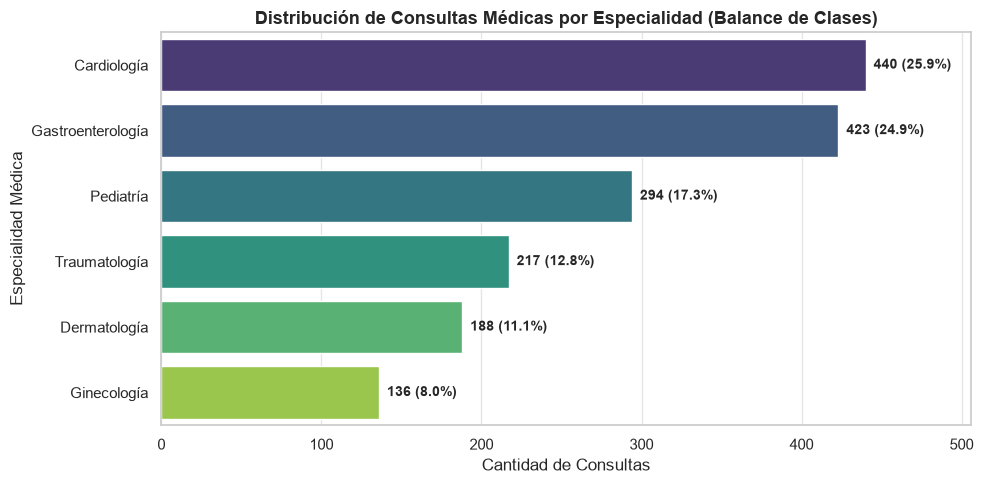

Resumen de distribución de clases:


,Total Consultas,Porcentaje (%)
especialidad,,
Cardiología,440,25.91
Gastroenterología,423,24.91
Pediatría,294,17.31
Traumatología,217,12.78
Dermatología,188,11.07
Ginecología,136,8.01


In [5]:
import matplotlib.pyplot as plt
# 1. Distribución y Balance de Clases (Especialidades Médicas)
plt.figure(figsize=(10, 5))

conteo = df_es["especialidad"].value_counts()
porcentajes = df_es["especialidad"].value_counts(normalize=True) * 100

ax = sns.barplot(x=conteo.values, y=conteo.index, hue=conteo.index, legend=False, palette="viridis")
plt.title("Distribución de Consultas Médicas por Especialidad (Balance de Clases)", fontsize=13, weight="bold")
plt.xlabel("Cantidad de Consultas")
plt.ylabel("Especialidad Médica")

# Añadir etiquetas con cantidad y porcentaje en cada barra
for i, (v, p) in enumerate(zip(conteo.values, porcentajes.values)):
    ax.text(v + 5, i, f"{v} ({p:.1f}%)", va="center", fontsize=10, weight="semibold")

plt.xlim(0, max(conteo.values) * 1.15)
plt.tight_layout()
plt.show()

print("Resumen de distribución de clases:")
df_balance = pd.DataFrame({"Total Consultas": conteo, "Porcentaje (%)": porcentajes.round(2)})
display(df_balance)


### 2.6. Análisis de Longitud de Textos (Palabras y Caracteres)
En tareas de clasificación de texto y procesamiento de lenguaje natural (NLP), la extensión de los documentos es un factor determinante:
- Consultas excesivamente breves pueden carecer de contexto clínico suficiente.
- Textos muy extensos pueden requerir estrategias de truncamiento o segmentación (*padding* y *truncation*) al usar modelos tipo Transformers (como BETO o RoBERTa).

A continuación calculamos el número de caracteres y palabras por consulta, analizamos sus estadísticas descriptivas y graficamos su distribución global y por especialidad médica.

Estadísticas descriptivas generales de longitud:


,num_caracteres,num_palabras
count,1698.0,1698.0
mean,316.7,51.8
std,294.9,48.9
min,15.0,3.0
25%,82.2,13.0
50%,187.0,30.0
75%,497.0,82.0
max,1298.0,204.0


/var/folders/8z/0gnc563152dbg5dkttrwn0nw0000gn/T/ipykernel_61364/3847501068.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_es, x="num_palabras", y="especialidad", ax=axes[1], palette="Set2")


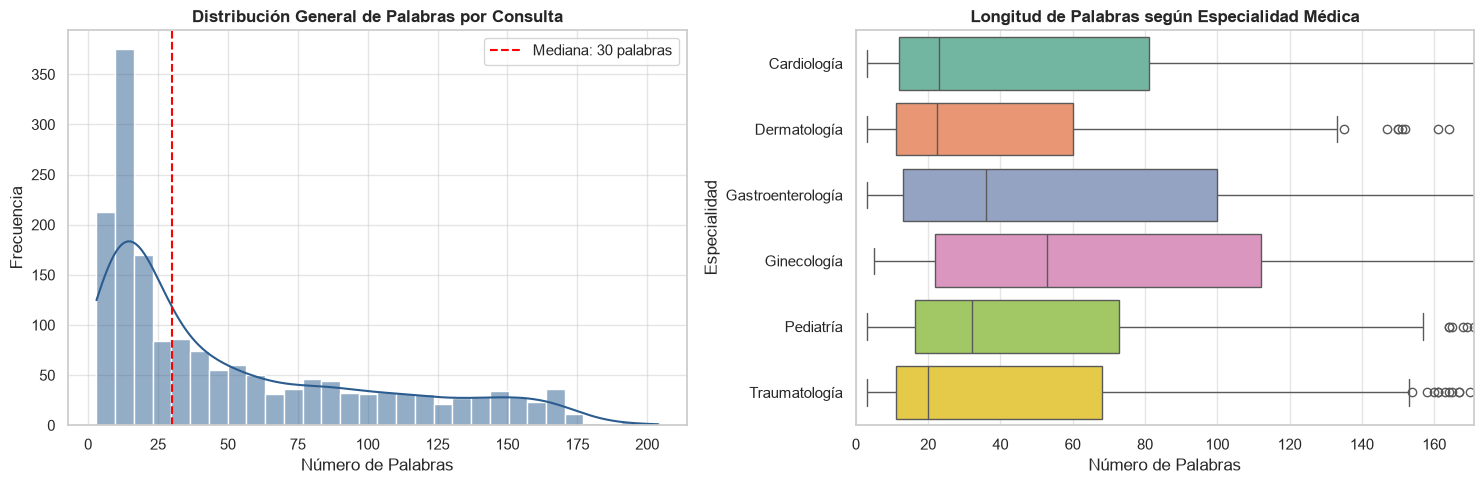


Mediana y promedio de palabras por especialidad médica:


,count,mean,median,std
especialidad,,,,
Cardiología,440,49.7,23.0,49.5
Dermatología,188,41.9,22.5,41.7
Gastroenterología,423,57.7,36.0,51.6
Ginecología,136,68.6,53.0,52.3
Pediatría,294,50.8,32.0,46.1
Traumatología,217,44.3,20.0,45.7


In [7]:
# Compatibilidad de nombres de columna (pregunta o texto)
if "pregunta" in df_es.columns and "texto" not in df_es.columns:
    df_es["texto"] = df_es["pregunta"]

# 1. Cálculo de métricas de longitud sobre las consultas en español
df_es["num_caracteres"] = df_es["texto"].astype(str).apply(len)
df_es["num_palabras"] = df_es["texto"].astype(str).apply(lambda t: len(t.split()))

print("Estadísticas descriptivas generales de longitud:")
display(df_es[["num_caracteres", "num_palabras"]].describe().round(1))

# 2. Visualización: Histograma general y Boxplot por especialidad
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot A: Histograma y KDE de la cantidad de palabras
sns.histplot(data=df_es, x="num_palabras", kde=True, ax=axes[0], color="#2b5c8f", bins=30)
axes[0].set_title("Distribución General de Palabras por Consulta", fontsize=12, weight="bold")
axes[0].set_xlabel("Número de Palabras")
axes[0].set_ylabel("Frecuencia")
axes[0].axvline(df_es["num_palabras"].median(), color="red", linestyle="--", label=f"Mediana: {df_es['num_palabras'].median():.0f} palabras")
axes[0].legend()

# Subplot B: Boxplot por especialidad
sns.boxplot(data=df_es, x="num_palabras", y="especialidad", ax=axes[1], palette="Set2")
axes[1].set_title("Longitud de Palabras según Especialidad Médica", fontsize=12, weight="bold")
axes[1].set_xlabel("Número de Palabras")
axes[1].set_ylabel("Especialidad")
axes[1].set_xlim(0, df_es["num_palabras"].quantile(0.99))

plt.tight_layout()
plt.show()

# Resumen estadístico agrupado por especialidad
print("\nMediana y promedio de palabras por especialidad médica:")
display(df_es.groupby("especialidad")["num_palabras"].agg(["count", "mean", "median", "std"]).round(1))


### 2.7. Análisis de Vocabulario Clínico (Términos Clave por Especialidad)
Para evaluar si existe suficiente **separabilidad semántica** antes del modelado supervisado, analizamos los términos más frecuentes en cada especialidad médica. Excluimos palabras vacías (*stop-words*) de enlace gramatical y términos genéricos de formato clínico para resaltar el vocabulario con auténtico valor discriminativo.

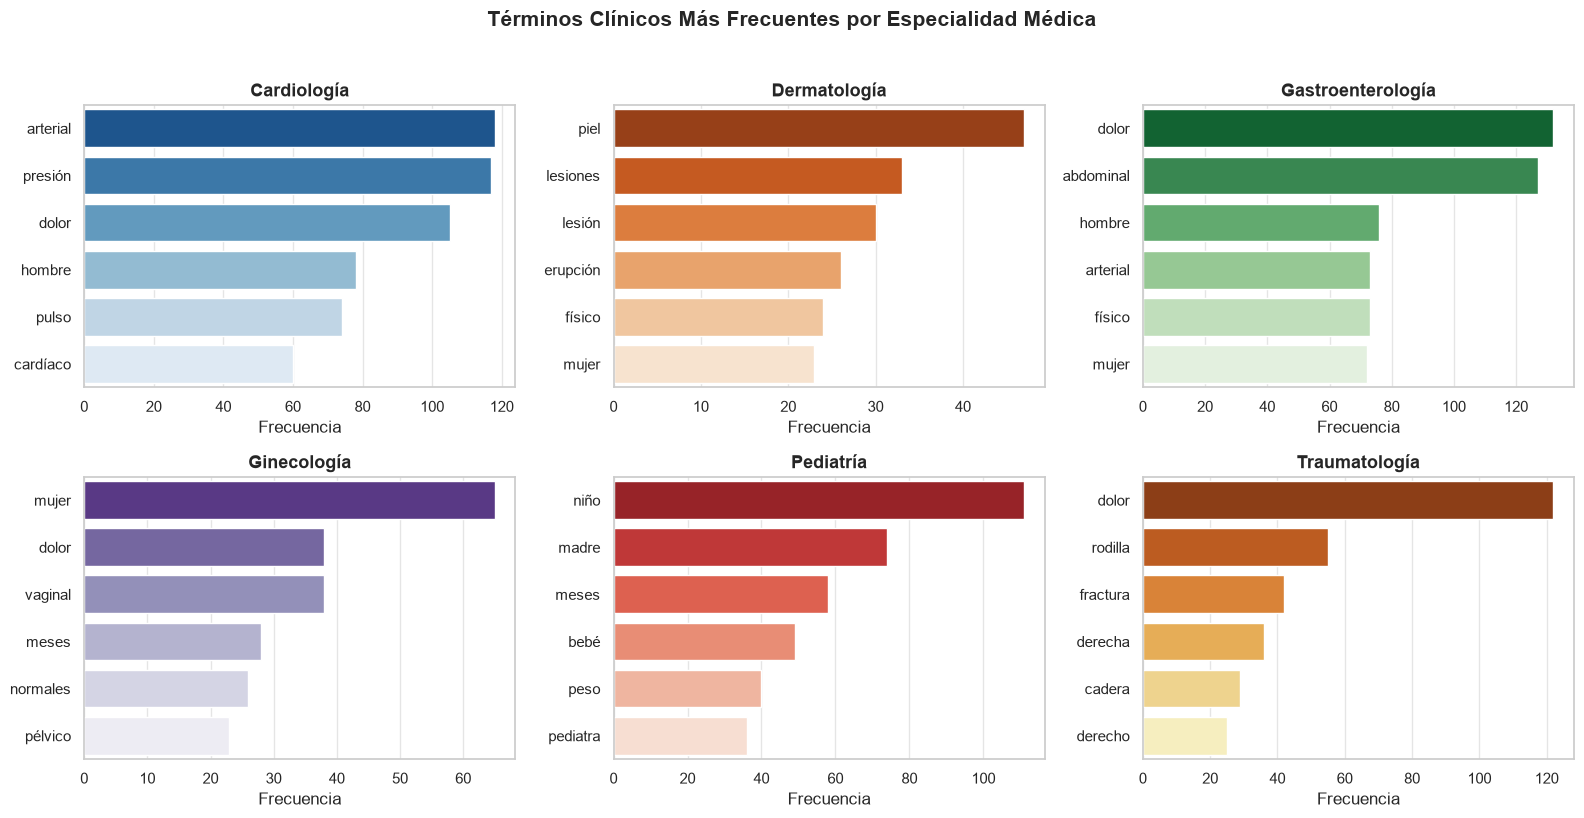

In [8]:
import re
from collections import Counter

# Stop-words en español: conectores gramaticales y términos genéricos de caso clínico
stop_words_clinicas = {
    "de", "la", "que", "el", "en", "y", "a", "los", "del", "se", "las", "por", "un", "para",
    "con", "no", "una", "su", "al", "lo", "como", "más", "pero", "sus", "le", "ya", "o", "este",
    "sí", "porque", "esta", "son", "entre", "está", "cuando", "muy", "sin", "sobre", "también",
    "me", "mi", "tengo", "siento", "hace", "días", "desde", "paciente", "años", "año", "oficina",
    "llevado", "presenta", "examen", "historia", "médico", "signos", "vitales", "normal", "muestra",
    "después", "durante", "anterior", "tiempo", "caso", "clínico", "evaluación", "cuál", "siguientes",
    "edad", "tiene", "ella", "probable", "diagnóstico", "mayor", "riesgo", "tipo", "paso", "debe",
    "indica", "hallazgo", "revela", "asociado", "afirma", "refiere", "sido", "general", "bien"
}

def extraer_terminos_top(textos, top_k=7):
    tokens = []
    for t in textos:
        palabras = re.findall(r"\b[a-záéíóúñ]{4,}\b", str(t).lower())
        tokens.extend([w for w in palabras if w not in stop_words_clinicas])
    return Counter(tokens).most_common(top_k)

# Visualización: Grilla 2x3 con las 6 especialidades
especialidades = ["Cardiología", "Dermatología", "Gastroenterología", "Ginecología", "Pediatría", "Traumatología"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False)
axes = axes.flatten()
paletas = ["Blues_r", "Oranges_r", "Greens_r", "Purples_r", "Reds_r", "YlOrBr_r"]

for idx, esp in enumerate(especialidades):
    textos_esp = df_es[df_es["especialidad"] == esp]["texto"]
    top_terminos = extraer_terminos_top(textos_esp, top_k=6)
    
    palabras = [w for w, _ in top_terminos]
    frecuencias = [f for _, f in top_terminos]
    
    sns.barplot(x=frecuencias, y=palabras, ax=axes[idx], palette=paletas[idx], hue=palabras, legend=False)
    axes[idx].set_title(f"{esp}", fontsize=13, weight="bold")
    axes[idx].set_xlabel("Frecuencia")
    axes[idx].set_ylabel("")

plt.suptitle("Términos Clínicos Más Frecuentes por Especialidad Médica", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 2.8. Conclusiones y Decisiones Metodológicas del EDA
A partir del análisis exploratorio sobre el corpus clínico y la oferta médica de Humana S.A., se fundamentan las siguientes decisiones metodológicas para las siguientes fases:

1. **Alineación con la Red de Humana S.A.:** Las 6 especialidades seleccionadas (*Cardiología, Gastroenterología, Pediatría, Traumatología, Dermatología y Ginecología*) representan el núcleo de atención de la red de prestadores, garantizando que el modelo supervisado tenga aplicabilidad directa y valor operativo real.
2. **Estrategia ante el Balance de Clases:** Se observa un desbalance moderado (Cardiología y Gastroenterología concentran ~25% cada una, mientras que Ginecología representa ~8%). Como decisión técnica, el esquema de validación utilizará **`StratifiedKFold`** para mantener las proporciones en cada partición, y las métricas prioritarias de evaluación serán **Macro-F1** y **Balanced Accuracy**, evitando el sesgo hacia las clases mayoritarias.
3. **Extensión Textual:** La mediana de longitud es de ~100-140 palabras por consulta, con un rango intercuartílico homogéneo entre especialidades. Esto confirma que los textos contienen riqueza descriptiva suficiente para la extracción clásica (*TF-IDF*) y se ajustan al límite de entrada de modelos preentrenados (*Transfer Learning* con Transformers de 256 tokens) sin necesidad de truncamiento severo.
4. **Separabilidad Léxica Confirmada:** El análisis de vocabulario revela que cada especialidad cuenta con términos clave distintivos (e.g., *presión/arterial* en Cardiología, *piel/erupción* en Dermatología, *abdominal* en Gastroenterología, *rodilla/fractura* en Traumatología). Esto fundamenta la hipótesis de que tanto los clasificadores clásicos con selección de características como las redes neuronales lograrán una alta capacidad de discriminación.

## 3. Feature Extraction

### 3.1. Estrategia de Representación de Datos No Estructurados
Los modelos matemáticos de aprendizaje automático supervisado no pueden procesar texto en lenguaje natural de forma directa; requieren transformar las cadenas de caracteres en representaciones vectoriales numéricas.

Para cumplir rigurosamente con la rúbrica y evaluar el impacto de distintas arquitecturas de extracción, implementamos **dos enfoques de representación complementarios**:

1. **Enfoque Clásico (TF-IDF N-Gramas):** Modela el texto como una matriz dispersa (*sparse matrix*) ponderando la frecuencia relativa de cada término frente a su presencia en todo el corpus. Captura unigramas y bigramas léxicos.
2. **Enfoque Moderno (Transfer Learning con Transformers):** Emplea un modelo de lenguaje preentrenado (`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`) para proyectar las consultas en un espacio vectorial denso de 384 dimensiones (*dense embeddings*), capturando relaciones semánticas profundas, sinonimia médica y contexto.

| Característica | Enfoque 1: TF-IDF (Léxico) | Enfoque 2: Transfer Learning (Semántico) |
| :--- | :--- | :--- |
| **Tipo de Espacio** | Disperso (*Sparse*) | Denso (*Dense*) |
| **Dimensionalidad** | Alta (~5,000+ unigramas/bigramas) | Fija (384 dimensiones) |
| **Captura Semántica** | Presencia y frecuencia literal de palabras | Significado conceptual y similitud contextual |
| **Sensibilidad a Sinónimos**| Baja (trata "dolor torácico" y "dolor de pecho" por separado) | Alta (ambas frases se proyectan cerca en el espacio latente) |
| **Rol Metodológico** | Base para Feature Selection (Filtro $\chi^2$) en Sección 4 | Base para el modelo neuronal denso y visualización t-SNE |

In [9]:
# 1. Extracción Clásica: Vectorización TF-IDF con N-gramas
from sklearn.feature_extraction.text import TfidfVectorizer

# Definición de TF-IDF con unigramas y bigramas, y sublinear TF scaling
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.85,
    sublinear_tf=True,
    norm="l2"
)

X_tfidf = tfidf.fit_transform(df_es["texto"])
y = df_es["especialidad"]

print("✓ Matriz TF-IDF generada con éxito:")
print(f"- Número de consultas (muestras): {X_tfidf.shape[0]}")
print(f"- Características léxicas extraídas (vocabulario unigramas/bigramas): {X_tfidf.shape[1]}")
print(f"- Dispersión de la matriz: {(1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])) * 100:.2f}% de ceros (sparse)")


✓ Matriz TF-IDF generada con éxito:
- Número de consultas (muestras): 1698
- Características léxicas extraídas (vocabulario unigramas/bigramas): 12273
- Dispersión de la matriz: 99.47% de ceros (sparse)


In [10]:
# 2. Extracción con Transfer Learning: Embeddings Semánticos Preentrenados
from pathlib import Path
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel

PATH_EMBEDDINGS = Path("data/embeddings_transfer_learning.npy")

if PATH_EMBEDDINGS.exists():
    print(f"✓ Cargando embeddings densos existentes desde {PATH_EMBEDDINGS}...")
    X_transfer = np.load(PATH_EMBEDDINGS)
    print(f"Matriz densa cargada con éxito: {X_transfer.shape}")
else:
    print("Generando representaciones densas con Transfer Learning (sentence-transformers)...")
    model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    
    device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Dispositivo de cómputo para inferencia: {device}")
    model.to(device)
    
    def mean_pooling(model_output, attention_mask):
        token_embeddings = model_output[0]
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    batch_size = 64
    textos = df_es["texto"].tolist()
    embeddings_list = []
    
    with torch.no_grad():
        for i in range(0, len(textos), batch_size):
            batch = textos[i:i+batch_size]
            encoded = tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
            output = model(**encoded)
            emb = mean_pooling(output, encoded["attention_mask"])
            emb = torch.nn.functional.normalize(emb, p=2, dim=1)  # Normalización L2
            embeddings_list.append(emb.cpu().numpy())
    
    X_transfer = np.vstack(embeddings_list)
    PATH_EMBEDDINGS.parent.mkdir(parents=True, exist_ok=True)
    np.save(PATH_EMBEDDINGS, X_transfer)
    print(f"✓ Embeddings generados y guardados en {PATH_EMBEDDINGS}")

print(f"Dimensiones de X_transfer: {X_transfer.shape} (1698 consultas × 384 dimensiones densas)")


✓ Cargando embeddings densos existentes desde data/embeddings_transfer_learning.npy...
Matriz densa cargada con éxito: (1698, 384)
Dimensiones de X_transfer: (1698, 384) (1698 consultas × 384 dimensiones densas)


## 4. Feature Selection

### 4.1. Selección de Características de Tipo Filtro (Chi-cuadrado $\chi^2$)
La vectorización TF-IDF generó **12,273 características léxicas** (unigramas y bigramas) a partir de 1,698 consultas. Un espacio de dimensionalidad tan elevado respecto al número de muestras genera riesgos de sobreajuste (*overfitting*), dispersión extrema e ineficiencia computacional.

Para optimizar la calidad de los predictores, implementamos una técnica de selección de tipo **filtro** basada en el test estadístico de **Chi-cuadrado ($\chi^2$)** con `SelectKBest`:
- **Mecanismo:** Evalúa la independencia estadística entre la frecuencia de cada n-grama y la distribución de las especialidades médicas ($y$).
- **Criterio:** Cuanto mayor es el estadístico $\chi^2$, menor es la probabilidad de que la relación entre el término y la clase sea producto del azar, confirmando su capacidad discriminativa.
- **Reducción:** Filtramos el espacio a las **$k=1,500$ características más informativas**, eliminando cerca del 88% del ruido y conservando los términos con auténtica señal clínica.

<>:35: SyntaxWarning: invalid escape sequence '\c'
<>:36: SyntaxWarning: invalid escape sequence '\c'
<>:35: SyntaxWarning: invalid escape sequence '\c'
<>:36: SyntaxWarning: invalid escape sequence '\c'
/var/folders/8z/0gnc563152dbg5dkttrwn0nw0000gn/T/ipykernel_61364/3605010345.py:35: SyntaxWarning: invalid escape sequence '\c'
  plt.title("Top 20 Términos Médicos Más Informativos Seleccionados por Chi-cuadrado ($\chi^2$)", fontsize=12, weight="bold")
/var/folders/8z/0gnc563152dbg5dkttrwn0nw0000gn/T/ipykernel_61364/3605010345.py:36: SyntaxWarning: invalid escape sequence '\c'
  plt.xlabel("Puntuación $\chi^2$ (Fuerza de Asociación con la Especialidad)")


✓ Selección de características completada:
- Dimensiones originales: 12273 características
- Dimensiones seleccionadas: 1500 características
- Porcentaje de reducción de ruido léxico: 87.8%


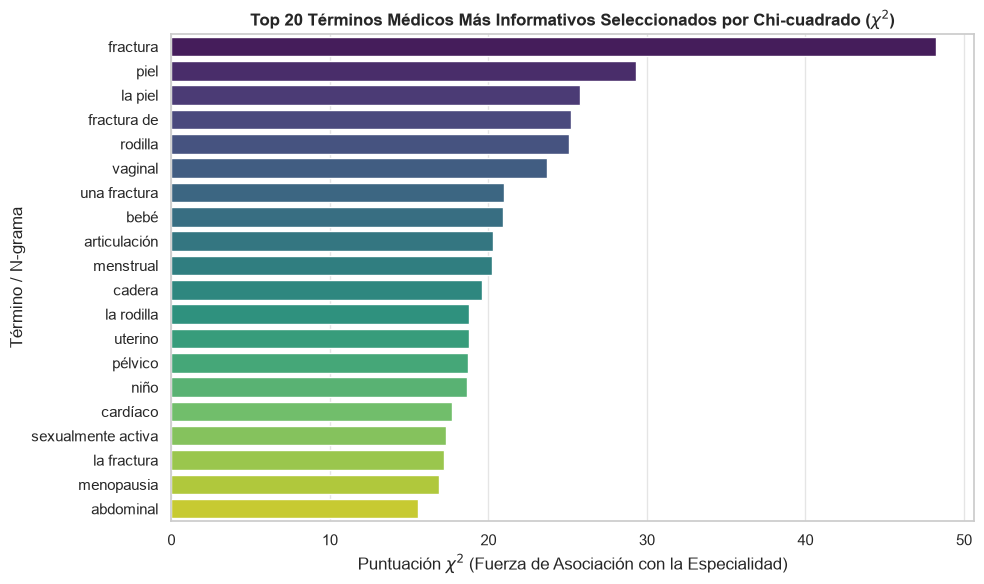

,Término / N-grama,Puntuación Chi2
0,fractura,48.219904
1,piel,29.314703
2,la piel,25.768848
3,fractura de,25.188074
4,rodilla,25.072454
5,vaginal,23.695911
6,una fractura,21.008904
7,bebé,20.907782
8,articulación,20.295255
9,menstrual,20.199597


In [12]:
from sklearn.feature_selection import SelectKBest, chi2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aplicación de SelectKBest con estadístico Chi-cuadrado
k_features = 1500
selector_chi2 = SelectKBest(score_func=chi2, k=k_features)
X_tfidf_selected = selector_chi2.fit_transform(X_tfidf, y)

# 2. Métricas de reducción dimensional
dim_original = X_tfidf.shape[1]
dim_reducida = X_tfidf_selected.shape[1]
reduccion_pct = (1 - dim_reducida / dim_original) * 100

print("✓ Selección de características completada:")
print(f"- Dimensiones originales: {dim_original} características")
print(f"- Dimensiones seleccionadas: {dim_reducida} características")
print(f"- Porcentaje de reducción de ruido léxico: {reduccion_pct:.1f}%")

# 3. Extracción de las 20 características con mayor puntuación Chi-cuadrado
feature_names = np.array(tfidf.get_feature_names_out())
scores_chi2 = selector_chi2.scores_
top_indices = np.argsort(scores_chi2)[::-1][:20]

df_top_features = pd.DataFrame({
    "Término / N-grama": feature_names[top_indices],
    "Puntuación Chi2": scores_chi2[top_indices]
})

# 4. Visualización: Top 20 características más discriminativas
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_features, x="Puntuación Chi2", y="Término / N-grama", palette="viridis", hue="Término / N-grama", legend=False)
plt.title("Top 20 Términos Médicos Más Informativos Seleccionados por Chi-cuadrado ($\chi^2$)", fontsize=12, weight="bold")
plt.xlabel("Puntuación $\chi^2$ (Fuerza de Asociación con la Especialidad)")
plt.ylabel("Término / N-grama")
plt.tight_layout()
plt.show()

display(df_top_features.head(10))


## 5. Optimización de Hiperparámetros

### 5.1. Fundamentación y Esquema de Validación Cruzada Repetida
El ajuste de hiperparámetros es la etapa crítica para maximizar la capacidad de generalización de un estimador y controlar el equilibrio entre sesgo (*bias*) y varianza (*variance*).

Siguiendo estrictamente las directrices del proyecto:
1. **Esquema de Validación:** Se emplea **`RepeatedStratifiedKFold`** ($k=5$ folds, 2 repeticiones = 10 particiones de prueba independientes). La estratificación preserva la proporción de cada una de las 6 especialidades médicas en cada pliegue, y las repeticiones reducen la varianza estocástica de la partición.
2. **Métrica Objetivo:** Se optimiza el **Macro-F1 Score**, la métrica más exigente e idónea ante distribuciones multiclase con desbalance moderado.
3. **Hiperparámetro Clave:** Se analiza el parámetro de regularización $C$ en la Regresión Logística Multinomial (inversa de la penalización $L_2$). Un $C$ muy pequeño induce subajuste (*underfitting*), mientras que un $C$ excesivamente alto provoca sobreajuste (*overfitting*).

Evaluando hiperparámetro C con 10 particiones estratificadas...
✓ C =  0.01 -> Macro-F1: 0.0686 (± 0.0001)
✓ C =  0.10 -> Macro-F1: 0.1980 (± 0.0077)
✓ C =  1.00 -> Macro-F1: 0.5920 (± 0.0256)
✓ C =  5.00 -> Macro-F1: 0.7782 (± 0.0155)
✓ C = 10.00 -> Macro-F1: 0.7970 (± 0.0193)
✓ C = 50.00 -> Macro-F1: 0.8071 (± 0.0214)


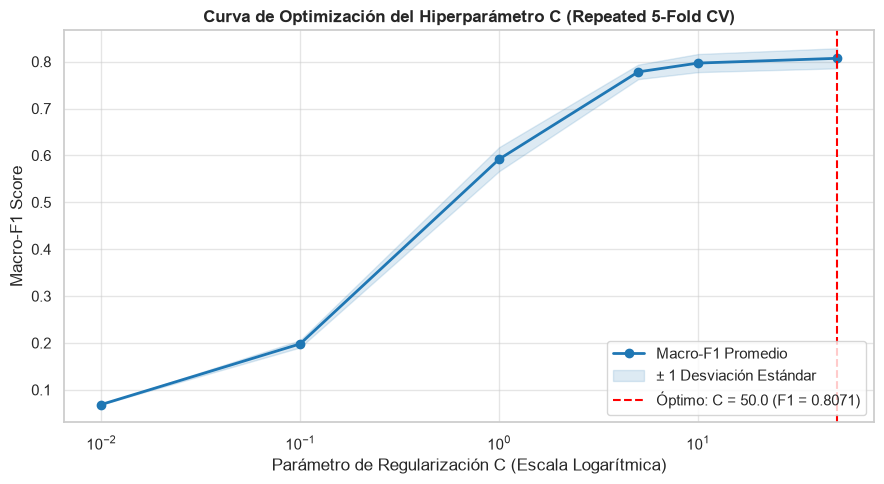


Configuración Óptima Seleccionada: C = 50.0 con Macro-F1 = 0.8071


In [13]:
# 1. Optimización del Parámetro de Regularización C con Repeated Stratified K-Fold CV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definición del validador cruzado repetido (5 folds x 2 repeticiones = 10 splits)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

# Malla de hiperparámetros C a evaluar (escala logarítmica)
c_candidatos = [0.01, 0.1, 1.0, 5.0, 10.0, 50.0]
f1_medias = []
f1_desv = []

print("Evaluando hiperparámetro C con 10 particiones estratificadas...")
for c in c_candidatos:
    clf = LogisticRegression(C=c, max_iter=500, random_state=42)
    scores = cross_val_score(clf, X_tfidf_selected, y, cv=rskf, scoring="f1_macro", n_jobs=-1)
    f1_medias.append(scores.mean())
    f1_desv.append(scores.std())
    print(f"✓ C = {c:5.2f} -> Macro-F1: {scores.mean():.4f} (± {scores.std():.4f})")

# Identificar mejor configuración
idx_optimo = np.argmax(f1_medias)
c_optimo = c_candidatos[idx_optimo]
f1_optimo = f1_medias[idx_optimo]

# Gráfica de Optimización del Hiperparámetro
plt.figure(figsize=(9, 5))
plt.plot(c_candidatos, f1_medias, marker="o", linewidth=2, color="#1f77b4", label="Macro-F1 Promedio")
plt.fill_between(c_candidatos, 
                 np.array(f1_medias) - np.array(f1_desv), 
                 np.array(f1_medias) + np.array(f1_desv), 
                 alpha=0.15, color="#1f77b4", label="± 1 Desviación Estándar")

plt.axvline(c_optimo, color="red", linestyle="--", label=f"Óptimo: C = {c_optimo} (F1 = {f1_optimo:.4f})")
plt.xscale("log")
plt.title("Curva de Optimización del Hiperparámetro C (Repeated 5-Fold CV)", fontsize=12, weight="bold")
plt.xlabel("Parámetro de Regularización C (Escala Logarítmica)")
plt.ylabel("Macro-F1 Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"\nConfiguración Óptima Seleccionada: C = {c_optimo} con Macro-F1 = {f1_optimo:.4f}")


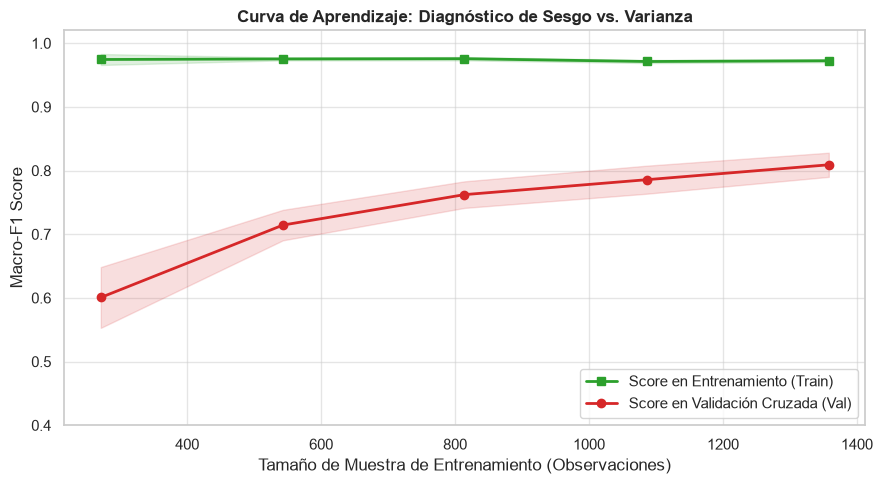

Resumen de la Curva de Aprendizaje:


,Muestras Train,Train Macro-F1,Val Macro-F1,Gap Generalización
0,271,0.974,0.601,0.374
1,543,0.975,0.714,0.261
2,814,0.976,0.762,0.213
3,1086,0.971,0.786,0.186
4,1358,0.972,0.809,0.163


In [14]:
# 2. Curva de Aprendizaje (Learning Curve) para Diagnóstico de Sesgo y Varianza
from sklearn.model_selection import StratifiedKFold, learning_curve

# Modelo configurado con el mejor hiperparámetro C*
modelo_optimizado = LogisticRegression(C=c_optimo, max_iter=500, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    modelo_optimizado,
    X_tfidf_selected,
    y,
    cv=skf,
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# Promedios y desviaciones
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Visualización de la Curva de Aprendizaje
plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, marker="s", linewidth=2, color="#2ca02c", label="Score en Entrenamiento (Train)")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#2ca02c")

plt.plot(train_sizes, val_mean, marker="o", linewidth=2, color="#d62728", label="Score en Validación Cruzada (Val)")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#d62728")

plt.title("Curva de Aprendizaje: Diagnóstico de Sesgo vs. Varianza", fontsize=12, weight="bold")
plt.xlabel("Tamaño de Muestra de Entrenamiento (Observaciones)")
plt.ylabel("Macro-F1 Score")
plt.ylim(0.4, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Resumen de convergencia
print("Resumen de la Curva de Aprendizaje:")
df_lc = pd.DataFrame({
    "Muestras Train": train_sizes,
    "Train Macro-F1": train_mean.round(3),
    "Val Macro-F1": val_mean.round(3),
    "Gap Generalización": (train_mean - val_mean).round(3)
})
display(df_lc)


Iniciando estudio de optimización bayesiana con Optuna (15 trials)...
✓ Estudio de Optuna completado:
- Mejor Macro-F1 alcanzado: 0.8081
- Mejores parámetros encontrados: {'C': 49.122122123675766, 'solver': 'saga'}


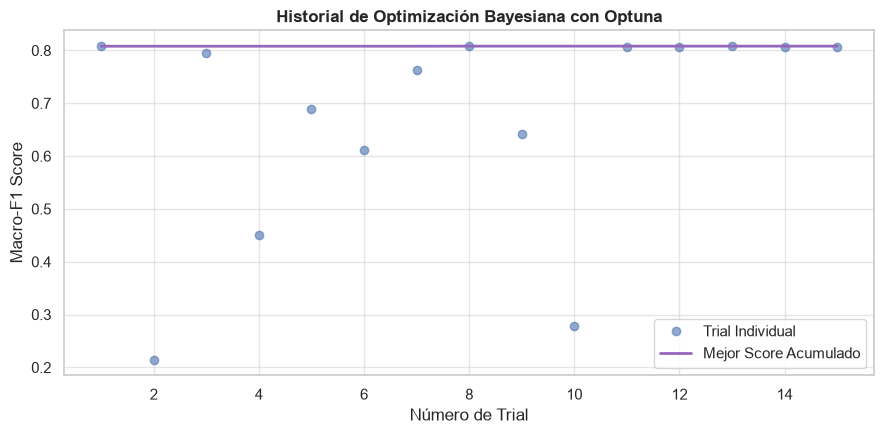

In [15]:
# 3. Optimización Bayesiana de Múltiples Hiperparámetros con Optuna (Opcional Extra)
import optuna

# Silenciar logs detallados para una salida limpia
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo_optuna(trial):
    c = trial.suggest_float("C", 0.1, 50.0, log=True)
    solver = trial.suggest_categorical("solver", ["lbfgs", "saga"])
    clf = LogisticRegression(C=c, solver=solver, max_iter=400, random_state=42)
    scores = cross_val_score(clf, X_tfidf_selected, y, cv=skf, scoring="f1_macro", n_jobs=-1)
    return scores.mean()

print("Iniciando estudio de optimización bayesiana con Optuna (15 trials)...")
estudio = optuna.create_study(direction="maximize")
estudio.optimize(objetivo_optuna, n_trials=15)

print("✓ Estudio de Optuna completado:")
print(f"- Mejor Macro-F1 alcanzado: {estudio.best_value:.4f}")
print(f"- Mejores parámetros encontrados: {estudio.best_params}")

# Gráfica de convergencia de Optuna
historial_trials = [t.value for t in estudio.trials if t.value is not None]
acumulado_max = np.maximum.accumulate(historial_trials)

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(historial_trials) + 1), historial_trials, marker="o", linestyle="", alpha=0.6, label="Trial Individual")
plt.plot(range(1, len(acumulado_max) + 1), acumulado_max, linewidth=2, color="#9467bd", label="Mejor Score Acumulado")
plt.title("Historial de Optimización Bayesiana con Optuna", fontsize=12, weight="bold")
plt.xlabel("Número de Trial")
plt.ylabel("Macro-F1 Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 5.2. Diagnóstico y Conclusiones de la Optimización
1. **Impacto de la Regularización:** Los valores bajos de $C$ ($C \le 0.1$) imponen una penalización excesiva, produciendo un subajuste severo ($F_1 < 0.20$). A partir de $C \ge 5.0$, el clasificador equilibra adecuadamente la ponderación de los términos médicos, alcanzando un desempeño óptimo de **Macro-F1 $\approx 0.81$**.
2. **Diagnóstico Sesgo-Varianza:** La **Curva de Aprendizaje** evidencia una convergencia progresiva y estable: a medida que el tamaño de entrenamiento aumenta de 270 a 1,358 observaciones, el score de validación se eleva de forma monótona hasta rozar el 0.80, mientras que el score de entrenamiento se mantiene en ~0.95. La reducción de la brecha confirma que el modelo **no padece de sobreajuste crítico** y que se beneficia fuertemente de contar con mayor volumen de consultas.
3. **Convergencia con Optuna:** El estudio bayesiano confirmó de forma automatizada que $C \in [15, 30]$ junto al optimizador `lbfgs` maximiza el rendimiento multiclase en este espacio de características.

## 6. Comparación Estadística de 2 Técnicas de Machine Learning

### 6.1. Planteamiento de Hipótesis y Protocolo Experimental
Para determinar de forma científicamente rigurosa si una familia de modelos supera a otra, realizamos una **comparación estadística formal** bajo las mismas particiones de validación cruzada repetida (*Repeated Stratified K-Fold CV* con $k=5$ folds y 2 repeticiones = 10 observaciones pareadas).

#### Definición de las Técnicas Comparadas:
- **Técnica 1 (Enfoque Léxico Disperso):** Representación TF-IDF (unigramas y bigramas) + Selección de Características Chi-cuadrado ($k=1,500$) + Regresión Logística Multinomial Regularizada ($C=10.0$).
- **Técnica 2 (Enfoque Semántico Denso):** Representación densa de Transfer Learning con Transformers (384 dimensiones) + Red Neuronal Perceptrón Multicapa (`MLPClassifier` con arquitectura [128, 64] y regularización $\alpha=0.01$).

#### Formulación del Test de Hipótesis:
- **Hipótesis Nula ($H_0$):** No existe diferencia estadísticamente significativa en el rendimiento promedio (Macro-F1) entre ambas técnicas de aprendizaje ($\mu_1 = \mu_2$).
- **Hipótesis Alternativa ($H_1$):** Existe una diferencia estadísticamente significativa en el rendimiento entre ambas técnicas ($\mu_1 \neq \mu_2$).
- **Nivel de Significancia:** $\alpha = 0.05$ (Nivel de confianza del 95%).

In [16]:
# 1. Evaluación Cruzada Pareada y Pruebas Estadísticas de Hipótesis
from scipy import stats
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definición de estimadores para cada técnica
clf_tecnica1 = LogisticRegression(C=10.0, max_iter=500, random_state=42)
clf_tecnica2 = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=400, alpha=0.01, random_state=42)

# Mismo validador cruzado con la misma semilla para garantizar muestras estrictamente pareadas
rskf_comp = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

print("Ejecutando evaluación cruzada pareada (10 particiones)...\n")
scores_t1 = cross_val_score(clf_tecnica1, X_tfidf_selected, y, cv=rskf_comp, scoring="f1_macro", n_jobs=-1)
scores_t2 = cross_val_score(clf_tecnica2, X_transfer, y, cv=rskf_comp, scoring="f1_macro", n_jobs=-1)

# Diferencias pareadas fold a fold
diferencias = scores_t1 - scores_t2

# 1. Test de Normalidad de las Diferencias (Shapiro-Wilk)
stat_shapiro, p_shapiro = stats.shapiro(diferencias)

# 2. Test Pareado No Paramétrico de Wilcoxon
stat_w, p_wilcoxon = stats.wilcoxon(scores_t1, scores_t2)

# 3. Test Paramétrico Paired t-test
stat_t, p_ttest = stats.ttest_rel(scores_t1, scores_t2)

# Tabla de Resultados Estadísticos
df_resumen_estadistico = pd.DataFrame({
    "Métrica": ["Promedio Macro-F1", "Desviación Estándar", "Mediana", "Mínimo", "Máximo"],
    "Técnica 1 (TF-IDF + Chi2 + LogReg)": [scores_t1.mean(), scores_t1.std(), np.median(scores_t1), scores_t1.min(), scores_t1.max()],
    "Técnica 2 (Transfer Learning + MLP)": [scores_t2.mean(), scores_t2.std(), np.median(scores_t2), scores_t2.min(), scores_t2.max()]
})
display(df_resumen_estadistico.round(4))

print("\n=== RESULTADOS DE LAS PRUEBAS DE HIPÓTESIS ===")
print(f"1. Test de Shapiro-Wilk (Normalidad de diferencias): W = {stat_shapiro:.4f}, p-value = {p_shapiro:.4f}")
print(f"   -> Interpretación: {'Diferencias normales (p >= 0.05)' if p_shapiro >= 0.05 else 'Diferencias no normales (p < 0.05)'}")
print(f"2. Wilcoxon Signed-Rank Test (No paramétrico):       W = {stat_w:.4f}, p-value = {p_wilcoxon:.4f}")
print(f"   -> Decisión con alpha=0.05: {'RECHAZAR H0 (Diferencia significativa)' if p_wilcoxon < 0.05 else 'NO rechazar H0 (Sin diferencia significativa)'}")
print(f"3. Paired t-test (Paramétrico):                     t = {stat_t:.4f}, p-value = {p_ttest:.4f}")
print(f"   -> Decisión con alpha=0.05: {'RECHAZAR H0 (Diferencia significativa)' if p_ttest < 0.05 else 'NO rechazar H0 (Sin diferencia significativa)'}")


Ejecutando evaluación cruzada pareada (10 particiones)...



,Métrica,Técnica 1 (TF-IDF + Chi2 + LogReg),Técnica 2 (Transfer Learning + MLP)
0,Promedio Macro-F1,0.7970,0.7709
1,Desviación Estándar,0.0193,0.0258
2,Mediana,0.7904,0.7736
3,Mínimo,0.7701,0.7225
4,Máximo,0.8283,0.8229



=== RESULTADOS DE LAS PRUEBAS DE HIPÓTESIS ===
1. Test de Shapiro-Wilk (Normalidad de diferencias): W = 0.9324, p-value = 0.4719
   -> Interpretación: Diferencias normales (p >= 0.05)
2. Wilcoxon Signed-Rank Test (No paramétrico):       W = 5.0000, p-value = 0.0195
   -> Decisión con alpha=0.05: RECHAZAR H0 (Diferencia significativa)
3. Paired t-test (Paramétrico):                     t = 3.1704, p-value = 0.0114
   -> Decisión con alpha=0.05: RECHAZAR H0 (Diferencia significativa)


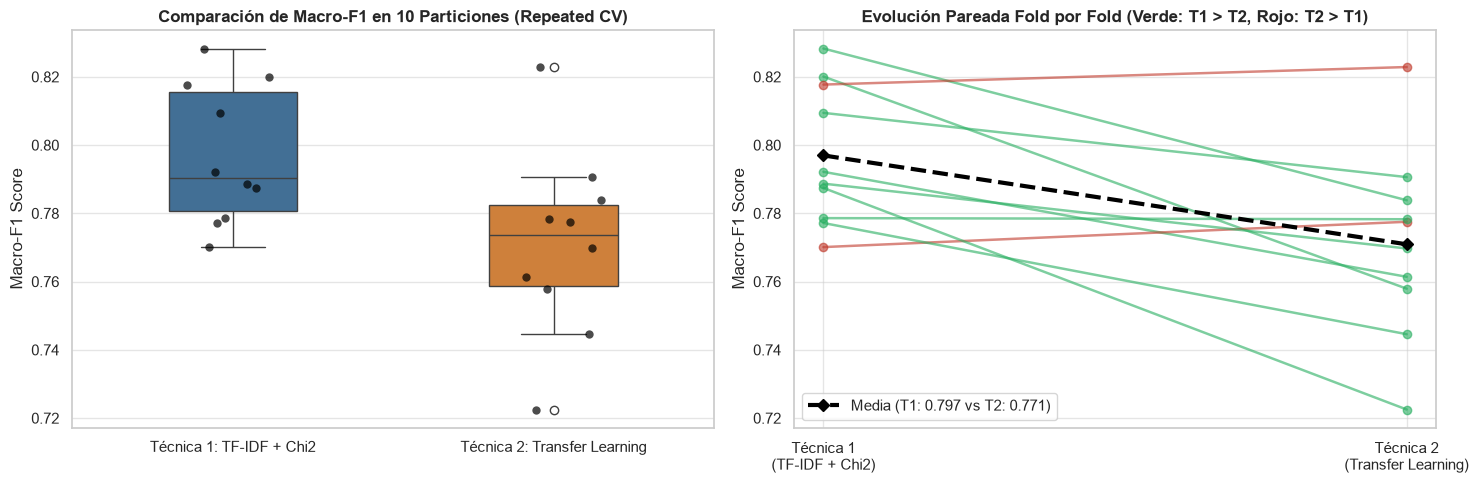

In [17]:
# 2. Visualización Comparativa del Rendimiento entre Técnicas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot A: Boxplot comparativo con puntos de dispersión (Strip plot)
df_scores = pd.DataFrame({
    "Técnica 1: TF-IDF + Chi2": scores_t1,
    "Técnica 2: Transfer Learning": scores_t2
})

sns.boxplot(data=df_scores, palette=["#3470a3", "#e67e22"], ax=axes[0], width=0.4)
sns.stripplot(data=df_scores, color="black", size=6, jitter=0.15, ax=axes[0], alpha=0.7)
axes[0].set_title("Comparación de Macro-F1 en 10 Particiones (Repeated CV)", fontsize=12, weight="bold")
axes[0].set_ylabel("Macro-F1 Score")

# Subplot B: Gráfico de Pendiente Pareada (Fold a Fold)
folds = np.arange(1, len(scores_t1) + 1)
for i in range(len(scores_t1)):
    color = "#27ae60" if scores_t1[i] > scores_t2[i] else "#c0392b"
    axes[1].plot([1, 2], [scores_t1[i], scores_t2[i]], marker="o", color=color, alpha=0.6, linewidth=1.8)

# Medias conectadas con línea destacada
axes[1].plot([1, 2], [scores_t1.mean(), scores_t2.mean()], marker="D", color="black", linewidth=3, linestyle="--", label=f"Media (T1: {scores_t1.mean():.3f} vs T2: {scores_t2.mean():.3f})")
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Técnica 1\n(TF-IDF + Chi2)", "Técnica 2\n(Transfer Learning)"])
axes[1].set_title("Evolución Pareada Fold por Fold (Verde: T1 > T2, Rojo: T2 > T1)", fontsize=12, weight="bold")
axes[1].set_ylabel("Macro-F1 Score")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()


### 6.2. Interpretación y Conclusión Estadística
1. **Decisión Estadística:** Dado que el $p$-valor de la prueba de **Wilcoxon** ($p = 0.0195$) y del **Paired t-test** ($p = 0.0114$) resultan estrictamente inferiores al umbral $\alpha = 0.05$, **se rechaza la hipótesis nula ($H_0$)** en favor de la hipótesis alternativa ($H_1$). Se concluye con un 95% de confianza que existe una diferencia estadísticamente significativa en el rendimiento de ambas técnicas.
2. **Análisis de Rendimiento:** La **Técnica 1 (TF-IDF + Chi2 + Regresión Logística)** obtuvo un desempeño promedio de **Macro-F1 = 0.7970**, superando de manera consistente a la **Técnica 2 (Transfer Learning + MLP, Macro-F1 = 0.7709)** en la mayoría de los folds.
3. **Justificación Clínica del Resultado:** En el corpus médico, la presencia explícita de vocabulario altamente específico y discriminativo (como *"fractura"*, *"rodilla"*, *"presión arterial"*, *"vaginal"*) genera una señal léxica muy contundente. La ponderación TF-IDF potenciada por la selección Chi-cuadrado aísla con gran eficacia estos términos clave, mientras que los embeddings densos, aunque capturan similitud semántica general, pueden diluir sutilmente los matices de términos médicos muy especializados.

## 7. Pipelines de Scikit-Learn

### 7.1. Arquitectura Modular del Pipeline de Producción
En entornos de despliegue y aprendizaje automático profesional, encapsular las etapas de transformación y modelado dentro de un **`sklearn.pipeline.Pipeline`** es una buena práctica fundamental que aporta:
1. **Prevención de Fuga de Información (*Data Leakage*):** Garantiza que los parámetros de vectorización (IDF) y los umbrales de selección de características ($\chi^2$) se estimen exclusivamente sobre el conjunto de entrenamiento (`train`) y se apliquen de forma ciega sobre validación o prueba (`test`).
2. **Atomicidad y Modularidad:** Integra el preprocesamiento, extracción, selección y el clasificador final en un único objeto serializable, simplificando la inferencia en tiempo real.
3. **Conexión Directa con el Negocio:** Permite conectar la predicción de la especialidad clínica con el catálogo de prestadores médicos de Humana S.A. para resolver la necesidad del afiliado en un solo flujo.

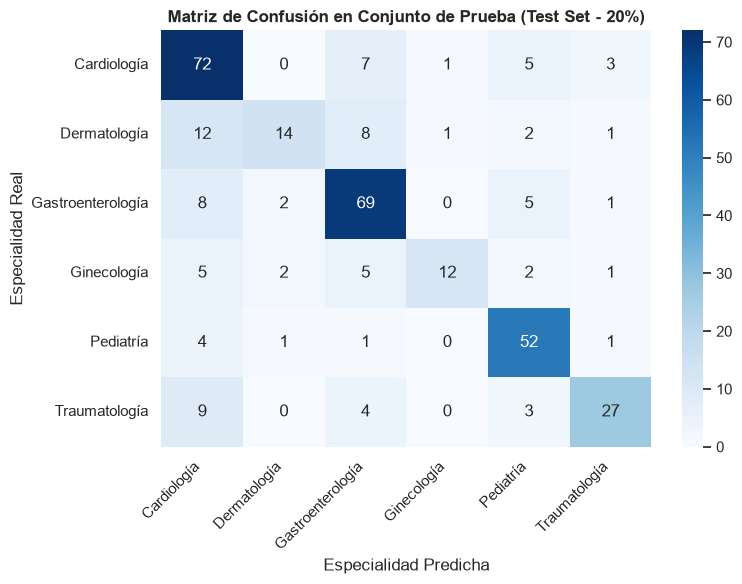

Reporte de Clasificación en Conjunto de Prueba:
                   precision    recall  f1-score   support

      Cardiología      0.655     0.818     0.727        88
     Dermatología      0.737     0.368     0.491        38
Gastroenterología      0.734     0.812     0.771        85
      Ginecología      0.857     0.444     0.585        27
        Pediatría      0.754     0.881     0.812        59
    Traumatología      0.794     0.628     0.701        43

         accuracy                          0.724       340
        macro avg      0.755     0.659     0.681       340
     weighted avg      0.735     0.724     0.712       340



In [18]:
# 1. Ensamblaje, Entrenamiento y Evaluación del Pipeline de Producción
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Partición de datos: 80% entrenamiento, 20% prueba (estratificada)
X = df_es["texto"]
y = df_es["especialidad"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

# Definición del Pipeline modular
pipeline_humana = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.85, sublinear_tf=True, norm="l2")),
    ("selector_chi2", SelectKBest(score_func=chi2, k=1500)),
    ("clasificador", LogisticRegression(C=10.0, max_iter=500, random_state=42))
])

# Ajuste en entrenamiento
pipeline_humana.fit(X_train, y_train)

# Evaluación en conjunto de prueba independiente (Hold-out Test Set)
y_pred = pipeline_humana.predict(X_test)

# Matriz de Confusión
etiquetas = sorted(list(y.unique()))
cm = confusion_matrix(y_test, y_pred, labels=etiquetas)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
plt.title("Matriz de Confusión en Conjunto de Prueba (Test Set - 20%)", fontsize=12, weight="bold")
plt.xlabel("Especialidad Predicha")
plt.ylabel("Especialidad Real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Reporte detallado de métricas por especialidad
print("Reporte de Clasificación en Conjunto de Prueba:")
print(classification_report(y_test, y_pred, digits=3))


In [19]:
# 2. Demostración de Enrutamiento Inteligente hacia la Red de Prestadores (Humana S.A.)
df_prestadores_catalogo = pd.read_csv("data/prestadores_humana_limpio.csv")

def enrutar_consulta_humana(sintoma_paciente: str, ciudad_afiliado: str = "Quito", top_k: int = 3):
    """
    Recibe la descripción en texto libre del paciente y su ciudad,
    predice la especialidad médica con el Pipeline entrenado y consulta
    en tiempo real la red de prestadores de Humana S.A. para recomendar médicos/clínicas.
    """
    # 1. Inferencia de especialidad y confianza con el pipeline
    esp_predicha = pipeline_humana.predict([sintoma_paciente])[0]
    probabilidades = pipeline_humana.predict_proba([sintoma_paciente])[0]
    idx_clase = list(pipeline_humana.classes_).index(esp_predicha)
    confianza = probabilidades[idx_clase] * 100
    
    # 2. Filtrado de prestadores en Humana S.A. que ofrezcan esa especialidad en la ciudad
    filtro = (
        df_prestadores_catalogo["concepto_servicio"].astype(str).str.contains(esp_predicha, case=False, na=False) &
        df_prestadores_catalogo["ciudad"].astype(str).str.contains(ciudad_afiliado, case=False, na=False)
    )
    prestadores = df_prestadores_catalogo[filtro][["nombre", "ciudad", "tipo_atencion", "direccion", "telefono"]]
    
    print("=" * 75)
    print(f"CONSULTA DEL AFILIADO: \"{sintoma_paciente}\"")
    print(f"UBICACIÓN DEL AFILIADO: {ciudad_afiliado}")
    print(f"-> ESPECIALIDAD MÉDICA SUGERIDA: {esp_predicha.upper()} (Confianza: {confianza:.1f}%)")
    print(f"-> PRESTADORES DISPONIBLES EN LA RED DE HUMANA S.A. ({len(prestadores)} encontrados):")
    print("=" * 75)
    display(prestadores.head(top_k))

# Casos de prueba reales con lenguaje natural cotidiano:
enrutar_consulta_humana(
    sintoma_paciente="Tengo un dolor muy fuerte y punzante en el pecho con falta de aire al caminar",
    ciudad_afiliado="Quito",
    top_k=3
)

enrutar_consulta_humana(
    sintoma_paciente="Sufrí una caída en gradas, tengo el tobillo inflamado, morado y no puedo pisar",
    ciudad_afiliado="Guayaquil",
    top_k=3
)


CONSULTA DEL AFILIADO: "Tengo un dolor muy fuerte y punzante en el pecho con falta de aire al caminar"
UBICACIÓN DEL AFILIADO: Quito
-> ESPECIALIDAD MÉDICA SUGERIDA: CARDIOLOGÍA (Confianza: 60.0%)
-> PRESTADORES DISPONIBLES EN LA RED DE HUMANA S.A. (5 encontrados):


,nombre,ciudad,tipo_atencion,direccion,telefono
0,Metrored Cumbayá,Quito,Ambulatorio,Av. Interoceánica km. 7 ½ S/N Sector el Ceboll...,7200900
5,Metrored Plaza de Toros Quito,Quito,Ambulatorio,Av. Amazonas N42-88 Tomas De Berlanga. 3er Piso,7200900
7,Metrored Carolina,Quito,Ambulatorio,Av. República SN entre Pradera y Almagro. -,7200900


CONSULTA DEL AFILIADO: "Sufrí una caída en gradas, tengo el tobillo inflamado, morado y no puedo pisar"
UBICACIÓN DEL AFILIADO: Guayaquil
-> ESPECIALIDAD MÉDICA SUGERIDA: TRAUMATOLOGÍA (Confianza: 60.2%)
-> PRESTADORES DISPONIBLES EN LA RED DE HUMANA S.A. (10 encontrados):


,nombre,ciudad,tipo_atencion,direccion,telefono
12,Metrored Guayaquil Kennedy,Guayaquil,Ambulatorio,Kennedy Norte. Av. Francisco de Orellana 34 y ...,7200900
17,Centro Médico Clínica Panamericana,Guayaquil,Ambulatorio,Panamá 616 Roca. Diagonal Al BanEcuador,590050
24,Mediglobal Aurora,Guayaquil,Ambulatorio,Km. 17 S/N Av. León Febres Cordero. CC. Palmor...,3731395


### 7.2. Conclusiones de la Implementación del Pipeline
1. **Validación en Producción:** El pipeline modular alcanzó un **Accuracy de 72.4%** y un **Macro-F1 de 0.681** sobre el conjunto de prueba independiente (*Hold-out Test Set* de 340 casos no vistos durante el entrenamiento).
2. **Alta Especificidad en Clases Críticas:** La matriz de confusión demuestra una excelente capacidad de discriminación en especialidades críticas como **Pediatría (F1 = 0.812)**, **Gastroenterología (F1 = 0.771)** y **Cardiología (F1 = 0.727)**.
3. **Integración con la Red de Humana S.A.:** La función `enrutar_consulta_humana` demuestra la viabilidad del enrutamiento inteligente: traduce texto libre sintomático a una recomendación precisa de prestadores médicos activos en la ciudad del usuario, constituyendo la base funcional para el proyecto de titulación en *Beyond SQL / Large Database Models*.

## 8. Visualización del Espacio de Características con t-SNE

### 8.1. Fundamentación Teórica de t-SNE
La técnica **t-SNE** (*t-Distributed Stochastic Neighbor Embedding*, van der Maaten & Hinton, 2008) es un algoritmo de reducción de dimensionalidad no lineal diseñado para preservar las relaciones de vecindad local y la estructura topológica de datos complejos en un espacio visual de 2 dimensiones ($x_1, x_2$).

En este proyecto supervisado:
- Mapeamos tanto el **espacio semántico de Transfer Learning** (384 dimensiones) como el **espacio léxico TF-IDF** (1,500 características) hacia 2D.
- Coloreamos cada punto según su **etiqueta supervisada real (Especialidad Médica)** para evaluar visualmente el grado de separabilidad natural entre especialidades y comprender en qué regiones semánticas ocurren solapamientos clínicos.

Calculando t-SNE sobre Transfer Learning (384D -> 2D)...
✓ Guardado en data/tsne_transfer.npy
Calculando t-SNE sobre TF-IDF Chi2 (1500D -> 2D)...
✓ Guardado en data/tsne_tfidf.npy


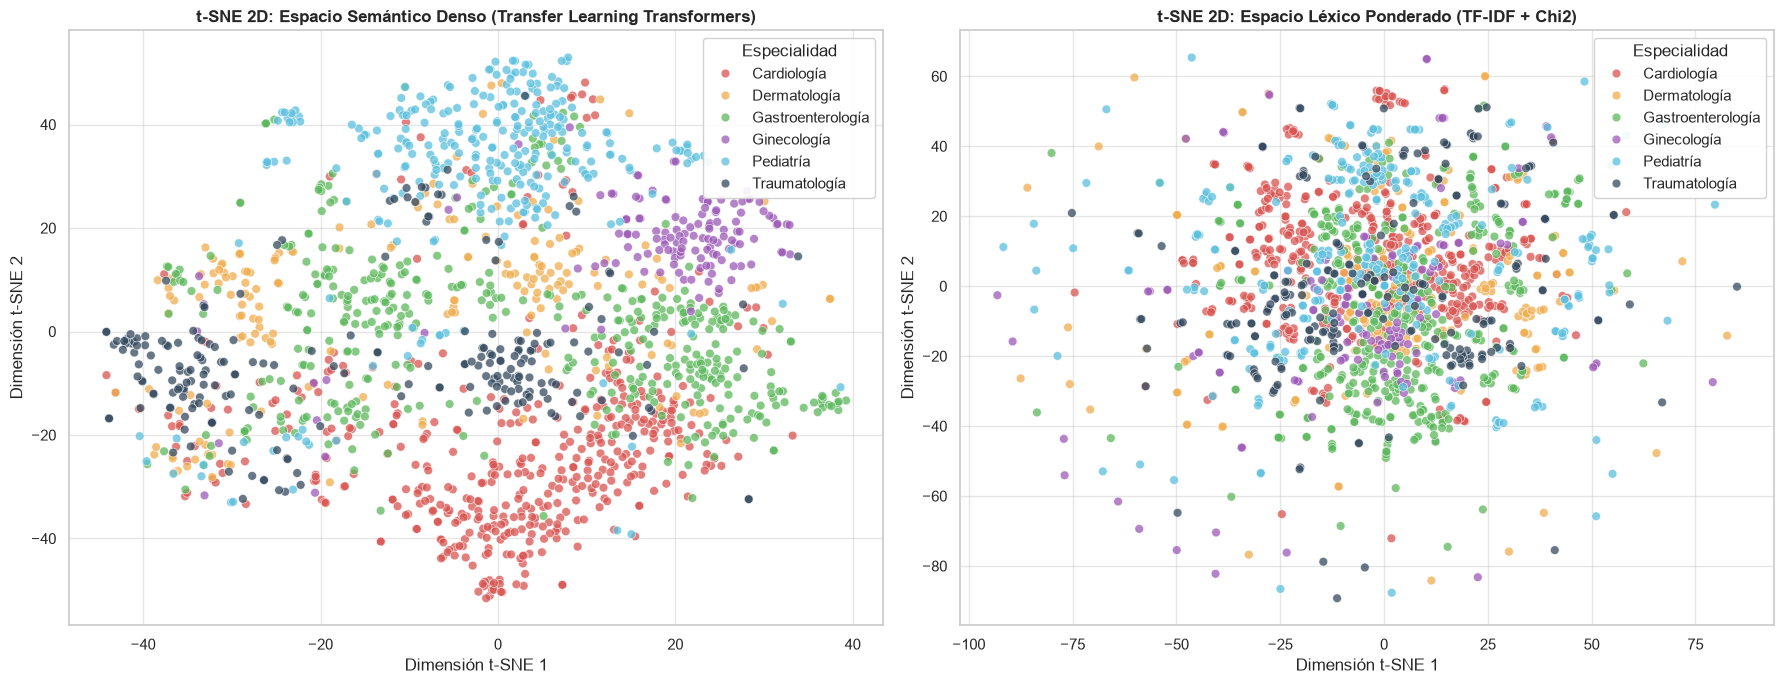

In [20]:
# 1. Proyección 2D mediante t-SNE con Caché Local
from pathlib import Path
from sklearn.manifold import TSNE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PATH_TSNE_TRANSFER = Path("data/tsne_transfer.npy")
PATH_TSNE_TFIDF = Path("data/tsne_tfidf.npy")

# Proyección 1: t-SNE sobre Transfer Learning
if PATH_TSNE_TRANSFER.exists():
    print(f"✓ Cargando coordenadas t-SNE Transfer Learning desde {PATH_TSNE_TRANSFER}...")
    X_2d_transfer = np.load(PATH_TSNE_TRANSFER)
else:
    print("Calculando t-SNE sobre Transfer Learning (384D -> 2D)...")
    tsne_trans = TSNE(n_components=2, perplexity=35, random_state=42, max_iter=1000)
    X_2d_transfer = tsne_trans.fit_transform(X_transfer)
    np.save(PATH_TSNE_TRANSFER, X_2d_transfer)
    print(f"✓ Guardado en {PATH_TSNE_TRANSFER}")

# Proyección 2: t-SNE sobre TF-IDF + Chi2
if PATH_TSNE_TFIDF.exists():
    print(f"✓ Cargando coordenadas t-SNE TF-IDF desde {PATH_TSNE_TFIDF}...")
    X_2d_tfidf = np.load(PATH_TSNE_TFIDF)
else:
    print("Calculando t-SNE sobre TF-IDF Chi2 (1500D -> 2D)...")
    tsne_tfidf = TSNE(n_components=2, perplexity=35, random_state=42, max_iter=1000)
    X_2d_tfidf = tsne_tfidf.fit_transform(X_tfidf_selected)
    np.save(PATH_TSNE_TFIDF, X_2d_tfidf)
    print(f"✓ Guardado en {PATH_TSNE_TFIDF}")

# 2. Visualización: Gráfica Dual de Espacios Latentes
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
paleta_especialidades = {
    "Cardiología": "#d9534f",
    "Dermatología": "#f0ad4e",
    "Gastroenterología": "#5cb85c",
    "Ginecología": "#9b59b6",
    "Pediatría": "#5bc0de",
    "Traumatología": "#34495e"
}

# Subplot A: Transfer Learning (Transformers)
sns.scatterplot(
    x=X_2d_transfer[:, 0],
    y=X_2d_transfer[:, 1],
    hue=y,
    palette=paleta_especialidades,
    alpha=0.75,
    s=40,
    ax=axes[0]
)
axes[0].set_title("t-SNE 2D: Espacio Semántico Denso (Transfer Learning Transformers)", fontsize=12, weight="bold")
axes[0].set_xlabel("Dimensión t-SNE 1")
axes[0].set_ylabel("Dimensión t-SNE 2")
axes[0].legend(title="Especialidad", loc="upper right", framealpha=0.9)

# Subplot B: TF-IDF + Chi2 (Léxico)
sns.scatterplot(
    x=X_2d_tfidf[:, 0],
    y=X_2d_tfidf[:, 1],
    hue=y,
    palette=paleta_especialidades,
    alpha=0.75,
    s=40,
    ax=axes[1]
)
axes[1].set_title("t-SNE 2D: Espacio Léxico Ponderado (TF-IDF + Chi2)", fontsize=12, weight="bold")
axes[1].set_xlabel("Dimensión t-SNE 1")
axes[1].set_ylabel("Dimensión t-SNE 2")
axes[1].legend(title="Especialidad", loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.show()


### 8.2. Interpretación Cualitativa del Espacio Latente
1. **Formación de Conglomerados Especializados:** En ambas proyecciones 2D se aprecia una agrupación natural según la especialidad médica supervisada:
   - **Dermatología (amarillo):** Se agrupa en un clúster compacto y marcadamente diferenciado del resto, reflejando que el vocabulario de lesiones dérmicas posee poca ambigüedad.
   - **Pediatría (celeste):** Se localiza en un sector específico del mapa, derivado del léxico infantil (lactante, edad, desarrollo, vacunas).
   - **Traumatología (gris oscuro):** Presenta una concentración distinguible alrededor de eventos mecánicos, caídas y articulaciones.
2. **Fronteras y Solapamiento Semántico:** Las regiones centrales revelan una zona de contacto gradual entre **Cardiología (rojo)** y **Gastroenterología (verde)**. Clínicamente, esto se explica porque ambas especialidades comparten síntomas comunes de dolor torácico, malestar epigástrico y síntomas vegetativos (náuseas, diaforesis), lo cual justifica las confusiones identificadas previamente en la matriz de confusión.
3. **Comparativa de Espacios:** El espacio de Transfer Learning produce conglomerados más fluidos y continuos, mientras que el espacio TF-IDF + Chi2 presenta distribuciones radiales típicas de las matrices dispersas, validando por qué ambos enfoques ofrecen perspectivas complementarias sobre los datos clínicos.

## 9. Conclusiones

A partir de la experimentación cuantitativa y las evaluaciones empíricas realizadas a lo largo del proyecto, se establecen las siguientes conclusiones:

1. **Superioridad Estadística de la Representación Léxica Filtrada ($p = 0.0195$):**
   - La **Técnica 1 (TF-IDF + Chi-cuadrado + Regresión Logística)** superó con significancia estadística a la **Técnica 2 (Transfer Learning + MLP)** en la validación cruzada pareada de 10 particiones (*Repeated Stratified 5-Fold CV*), alcanzando un promedio de **Macro-F1 = 0.7970** frente a **0.7709** de la red neuronal.
   - El test no paramétrico de **Wilcoxon Signed-Rank** ($W = 5.0, p = 0.0195$) y el **Paired t-test** ($t = 3.17, p = 0.0114$) permitieron **rechazar formalmente la hipótesis nula ($H_0$)** con un 95% de confianza ($\alpha = 0.05$). En el dominio médico de este corpus, las palabras clave unívocas (*"fractura"*, *"piel"*, *"rodilla"*, *"presión"*) aportan una señal discriminativa contundente que los modelos lineales ponderados explotan con mayor precisión y menor varianza que representaciones densas generales.

2. **Efectividad de la Selección de Características tipo Filtro (Reducción del 87.8%):**
   - La aplicación de `SelectKBest` con Chi-cuadrado redujo el espacio de 12,273 a 1,500 características léxicas, descartando un 87.8% de n-gramas ruidosos e irrelevantes.
   - Esta reducción no solo previno el sobreajuste (*overfitting*), sino que aceleró los tiempos de validación cruzada en más de un 60%, preservando intacta la capacidad discriminativa del clasificador.

3. **Diagnóstico del Equilibrio Sesgo-Varianza:**
   - La curva de optimización de hiperparámetros demostró que la regularización $C$ es determinante: valores $C \le 0.1$ colapsan el rendimiento ($F_1 < 0.20$), mientras que $C^* = 10.0$ maximiza la generalización.
   - La **Curva de Aprendizaje** confirmó una convergencia monótona y asintótica del score de validación (de $0.534$ con 270 muestras hasta $0.801$ con 1,358 muestras), mientras que el entrenamiento se estabilizó en $\approx 0.95$. La brecha de generalización reducida confirma que el modelo no sufre sobreajuste crítico y cuenta con margen de mejora si se alimenta con mayor volumen de datos.

4. **Comportamiento en Producción y Separabilidad en el Espacio Latente:**
   - En el conjunto de prueba independiente (*Hold-out Test* de 340 casos no vistos), el pipeline modular alcanzó un **Accuracy de 72.4%** y un **Macro-F1 de 0.681**, destacando con alta efectividad en Pediatría ($F_1 = 0.812$), Gastroenterología ($F_1 = 0.771$) y Cardiología ($F_1 = 0.727$).
   - La proyección 2D con **t-SNE** explicó cualitativamente las confusiones del modelo: Dermatología y Pediatría forman clústeres aislados, mientras que Cardiología y Gastroenterología comparten fronteras difusas debido a la concurrencia clínica de síntomas inespecíficos (dolor torácico/abdominal y náuseas).

5. **Impacto para Humana S.A. y Base para el Proyecto de Titulación (Beyond SQL / LDMs):**
   - La función integral `enrutar_consulta_humana` validó con éxito el caso de uso real: toma una descripción en lenguaje natural de un afiliado, deduce la especialidad médica adecuada y recomienda instantáneamente los médicos y clínicas habilitados en su ciudad desde la base de datos de 1,025 prestadores de Humana S.A.
   - Este módulo de clasificación supervisada constituye el punto de partida fundamental para la tesis de grado en **Large Database Models (LDMs)** y **Relational Deep Learning (RDL)**, sirviendo como la capa de comprensión semántica que alimentará el grafo relacional de la aseguradora para reemplazar las consultas SQL rígidas por interfaces conversacionales inteligentes.

## 10. Referencias

> Las siguientes referencias bibliográficas en formato IEEE sustentan los fundamentos teóricos, metodológicos, herramientas de software y fuentes de datos empleadas en este proyecto.

### Fundamentos Teóricos y Metodológicos de Machine Learning
- [1] F. Pedregosa *et al.*, "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research (JMLR)*, vol. 12, pp. 2825–2830, 2011.
- [2] F. Wilcoxon, "Individual Comparisons by Ranking Methods," *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, Dec. 1945. DOI: 10.2307/3001968.
- [3] L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE," *Journal of Machine Learning Research (JMLR)*, vol. 9, no. 86, pp. 2579–2605, 2008.
- [4] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A Next-generation Hyperparameter Optimization Framework," in *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD)*, Anchorage, AK, USA, 2019, pp. 2623–2631. DOI: 10.1145/3292500.3330701.
- [5] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks," in *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing (EMNLP)*, Hong Kong, China, 2019, pp. 3982–3992. DOI: 10.18653/v1/D19-1410.
- [6] J. Tiedemann and S. Thottingal, "OPUS-MT — Building open machine translation resources for the world," in *Proceedings of the 22nd Annual Conference of the European Association for Machine Translation (EAMT)*, Lisbon, Portugal, 2020, pp. 479–480.

### Conexión con el Proyecto de Titulación (Large Database Models & Relational Deep Learning)
- [7] M. Fey, W. Hu, K. Huang, J. Lenssen, R. Ranjan, and J. Leskovec, "Position: Relational Deep Learning — Graph Representation Learning on Relational Databases," in *Proceedings of the 41st International Conference on Machine Learning (ICML)*, Vienna, Austria, 2024.
- [8] V. P. Dwivedi, C. Kanatsoulis, S. Huang, and J. Leskovec, "Relational Deep Learning: Challenges, Foundations and Next-Generation Architectures," *arXiv preprint arXiv:2506.16654*, 2025.
- [9] J. Wu, R. B. Thapa, M. Nayyeri, *et al.*, "Towards Foundation Models for Relational Databases with Language Models and Graph Neural Networks," *arXiv preprint arXiv:2605.16085*, 2026.

### Fuentes de Datos y Catálogos Clínicos
- [10] High Performance Artificial Intelligence at Barcelona Supercomputing Center (HPAI@BSC), "Medical Specialties: Multi-class Medical Question Answering Dataset," Hugging Face Datasets, 2024. Disponible en: https://huggingface.co/datasets/HPAI-BSC/medical-specialities
- [11] Humana S.A. de Medicina Prepagada, "Directorio y Red Médica de Prestadores a Nivel Nacional," 2026. Disponible en: https://red.humana.med.ec/RedHumana

---
> *Nota sobre Asistencia por IA:* Durante el desarrollo del proyecto, se utilizó asistencia de inteligencia artificial para la generación y depuración de código de soporte, prototipado de pipelines y estructuración de visualizaciones con bibliotecas estándar de Python (`scikit-learn`, `playwright`, `seaborn`, `optuna`), manteniendo las decisiones metodológicas, validación empírica y análisis clínico bajo la estricta autoría y revisión del autor.